# 03 — Mapping logical SM ids to GPCs on the H100 NVL

**Goal.** The 132 SMs of this GPU are grouped into GPCs (graphics processing clusters). A GPC is the unit in which thread-block clusters are scheduled. It shares one SM-to-SM network for distributed shared memory and attaches to the L2 through its own crossbar port. Which logical SM id (`%smid`) belongs to which GPC is not documented, and it differs between cards because each die has a different set of disabled units. This experiment recovers the map for this card without privileged access, using three independent signals:

1. **Cluster co-scheduling:** which SMs the hardware ever places in the same cluster.
2. **Clock rates:** which SMs run at exactly the same clock rate.
3. **Hardware counters:** how many clusters the hardware counts per GPC.

The result is a table `%smid → GPC, GPC size, cluster capability, TPC mate`. It orders the SMs in every SM-pair and SM-to-L2 measurement that follows, and it defines what "same GPC" and "other GPC" mean when distances on the chip are discussed.

## Background

**SM, TPC, GPC.**
- Two SMs form a TPC (texture processing cluster).
- Up to nine TPCs (18 SMs) form a GPC.
- A complete GH100 die has 8 GPCs × 9 TPCs = 144 SMs. This product enables 132 SMs (66 TPCs), so 6 TPCs are disabled, and which ones differs from die to die. GPC sizes are therefore not uniform, and the composition is a property of the individual card.

**Logical SM ids.** A thread reads the id of the SM it runs on with `mov.u32 %r, %smid;`. The ids 0–131 are assigned by the driver; nothing in the programming model says which ids share a GPC or a TPC.

**Clusters are co-scheduled inside one GPC.** A kernel launched with a cluster dimension `CS` groups CTAs `c·CS … c·CS+CS−1` into cluster `c`. The hardware places all CTAs of a cluster at the same time, on SMs of one GPC; it waits until one GPC has room for the whole cluster. Inside the kernel each CTA reads `%smid`, `%clusterid.x` and `%cluster_ctarank`. Two consequences:
- Any two SMs that ever hosted CTAs of the same cluster are in the same co-scheduling domain. Joining all such pairs over many launches (union-find) gives the domains.
- A cluster of 16 fits only where 16 SMs of one GPC are free, so the largest clusters expose the GPCs directly. Smaller clusters (8, 4, 3, 2) reach smaller GPCs and leftover SMs, and changing the shared-memory size and block size between launches changes which SMs are free when a cluster is placed.

A co-scheduling domain is what the cluster scheduler treats as one unit. If some SMs of a GPC never share a cluster with the rest of it, they show up as separate small domains, and cluster placement alone cannot tell which GPC they belong to.

**Per-SM clock rate.** `%clock64` counts cycles of the SM that reads it, and `%globaltimer` is a nanosecond timer common to the whole chip. Their ratio over a long window is the SM's effective clock. Under the locked SM clock this rate varies slightly from launch to launch and differs between groups of SMs, while all SMs of a group show exactly the same rate. If each group is one clock domain, and each GPC is one clock domain, these groups are the GPCs. This experiment tests that hypothesis on the SMs whose GPC is known from cluster placement, and then uses the groups to place the SMs that cluster placement cannot place.

**Hardware counters.** Nsight Compute's `gpc__cgas_launched` counts clusters ("CGAs") launched per GPC unit and reports the sum, minimum, maximum and average over the GPC units. With one wave of clusters, these numbers follow from the GPC composition and can be predicted from the map.

**TPC mates.** The two SMs of a TPC share the TPC's front end. The working hypothesis is that `%smid` 2t and 2t+1 are the two SMs of TPC t. Cluster placement gives indirect evidence (pairs of ranks placed together); direct evidence would need a latency signature.

## Experimental setup

**Device and configuration.** NVIDIA H100 NVL, 132 SMs, 60 MiB L2, HBM3 at 2619 MHz; power limit 400 W, ECC on, MIG off; driver 580.126.20, CUDA 12.9 (`nvcc -arch=sm_90a -O3`). The SM clock is locked at 1635 MHz with `nvidia-smi -lgc`. Every recorded launch is followed by an NVML sample of the SM and memory clocks and the throttle reasons. A launch is flagged if a throttle reason is set or if the SM clock reads more than 15 MHz below the lock; the table below gives the count. The card is identified by its serial number (below), because the map belongs to this die.

**Co-scheduling probe.** Kernel `sleep_kernel`: every thread spins on `%clock64` for 100 000 cycles (≈ 61 µs, so all CTAs of a wave overlap). After the spin, thread 0 stores `{block, %smid, %clusterid.x, %cluster_ctarank, %cluster_nctarank, %is_explicit_cluster}`.
- The dynamic shared memory is allocated but not used: it only sets how many CTAs fit on an SM. 200 KB and 120 KB allow 1 CTA/SM; 80 KB allows 2.
- Launches use `cudaLaunchKernelEx` with `cudaLaunchAttributeClusterDimension = {CS,1,1}` and scheduling policy Default. Clusters of 16 need `cudaFuncAttributeNonPortableClusterSizeAllowed`.
- The grid is 1 or 3 waves: `waves × cudaOccupancyMaxActiveClusters × CS`.
- Configurations: CS ∈ {16, 8, 4, 3, 2} × waves ∈ {1, 3} × shared memory ∈ {200, 120, 80} KB × block ∈ {1024, 512} threads = 60.
- Each configuration gets 2 warm-ups, then 50 rounds. One round launches all 60 configurations in turn, so consecutive launches differ in cluster size, occupancy and grid.
- The host checks every record: all CTAs wrote, `clusterid = block / CS`, `rank = block % CS`, `nctarank = CS`, explicit cluster. It also counts clusters whose CTAs share an SM.

**Clock-domain probe.** Kernel `clockdom_kernel`: one 32-thread CTA per SM (132 CTAs, 200 KB of shared memory each); the host checks that all 132 `%smid` values are distinct and repeats the launch otherwise. Thread 0 does the following (SASS of the two edge loops):
```
CS2R R4, SR_GLOBALTIMERLO ;  CS2R R6, SR_CLOCKLO ;   ISETP.NE … ;  @!P0 BRA      // wait for a timer tick edge → (g0, c0)
CS2R R8, SR_GLOBALTIMERLO ;  CS2R R10, SR_CLOCKLO ;  IADD3 … ; ISETP.GE … ; @!P0 BRA   // until g ≥ g0 + 2^25 ns → (g1, c1)
```
- Both endpoints are the first reads after a `%globaltimer` tick, so `g1 − g0` is an exact number of nanoseconds (2²⁵ ns = 33.6 ms). The only error is the few-instruction edge-detection loop at each end.
- rate = (c1 − c0) / (g1 − g0). Its resolution is about 0.002 MHz.
- 2 warm-ups, then 50 launches.
- Two SMs share a clock domain if their rates differ by less than 0.02 MHz in **every** launch.

**Hardware counters.** One launch of `sleep_kernel` per CS ∈ {2, 3, 4, 8, 16} at one wave, with 200 KB (1 CTA/SM) and 80 KB (2 CTAs/SM), profiled with:
`ncu --clock-control none --cache-control none --metrics gpc__cgas_launched.{sum,min,max,avg},launch__cluster_max_active,sm__cycles_elapsed.avg.per_second,…`.
Per-instance values are not exported for this metric, so only the four roll-ups are available.

**Privileged cross-checks.** None that needs kernel-level access was run. The GPC/TPC disable masks are not readable without loading a kernel module, which this shared machine does not allow. MIG stays disabled; only the driver's list of MIG instance profiles was queried (`nvidia-smi mig -lgip`).

In [1]:
%matplotlib inline
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.patches import Patch, Rectangle
from IPython.display import display, Markdown

R = "results"
EXP = "03__sm_gpc_topology"
F = f"{R}/{EXP}__"
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#a35bd0", "#d4a20c", "#d6457a", "#4fb3c8", "#7a6e5c"]
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11, "figure.dpi": 110,
})
pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", 120)

runs = pd.read_csv(f"{R}/{EXP}__runs.csv")
status = runs.groupby("run_id")["status"].agg(lambda s: "complete" if "complete" in set(s) else "partial")
cmd = runs.dropna(subset=["started_iso"]).set_index("run_id")["cmdline"]
clog = pd.read_csv(F + "clock_log.csv")

def latest_complete(df, sub):
    ids = [r for r in df["run_id"].unique() if status.get(r) == "complete" and re.search(rf"gpc_probe {sub}(\s|$)", cmd.get(r, ""))]
    rid = max(ids)
    return df[df["run_id"] == rid].copy(), rid

edges, rid_e = latest_complete(pd.read_csv(F + "edges.csv"), "cosched")
clk, rid_c = latest_complete(pd.read_csv(F + "clock_domains.csv"), "clockdom")
ncu, rid_n = latest_complete(pd.read_csv(F + "ncu.csv"), "ncu")
mp = pd.read_csv(F + "map.csv")
mp = mp[(mp.run_id == rid_e) & (mp.clockdom_run_id == rid_c)].drop_duplicates("smid", keep="last").set_index("smid").sort_index()
N = int(edges.sm_count.iloc[0])

In [2]:
first = clog.iloc[0]
dev = pd.DataFrame({
    "GPU": [first.gpu_name], "SMs": [first.sm_count], "CUDA runtime": [first.cuda_version], "driver": [first.driver_version],
    "locked SM clock (requested)": [f"{int(clog.lock_sm_mhz.max())} MHz"],
    "SM clock reported by NVML (min–max over all samples)": [f"{clog.sm_clock_mhz.min()}–{clog.sm_clock_mhz.max()} MHz"],
    "memory clock (NVML)": [f"{clog.mem_clock_mhz.min()}–{clog.mem_clock_mhz.max()} MHz"],
    "board power (min–max)": [f"{clog.power_w.min():.0f}–{clog.power_w.max():.0f} W"],
    "GPU / HBM temperature max": [f"{clog.gpu_temp_c.max()} / {clog.mem_temp_c.max()} °C"],
})
card = open(F + "card.txt").read()
for key in ["Serial Number", "Board Part Number", "VBIOS Version", "GPU UUID"]:
    m = re.findall(rf"^\s*{key}\s*:\s*(\S+)", card, flags=re.M)
    dev[key.lower()] = [m[-1] if m else "n/a"]
display(dev.T.rename(columns={0: ""}))

r = runs.dropna(subset=["started_iso"])[["run_id", "cmdline"]].copy()
r["mode"] = r.cmdline.str.extract(r"gpc_probe (\w+)")[0]
r["status"] = r.run_id.map(status)
display(r[["run_id", "mode", "status"]].reset_index(drop=True))

launches = edges.drop_duplicates("launch_idx")
cfg = (launches.groupby(["cs", "waves", "smem_bytes", "block_threads"], sort=False)
       .agg(grid_blocks=("grid_blocks", "first"), launches=("launch_idx", "size")).reset_index())
cfg["clusters per launch"] = cfg.grid_blocks // cfg.cs
cfg["CTAs/SM allowed"] = np.where(cfg.smem_bytes > 120 * 1024 - 1, 1, 2)
cfg["smem"] = (cfg.smem_bytes // 1024).astype(str) + " KB"
display(cfg.pivot_table(index=["cs", "waves"], columns=["smem", "block_threads"], values="grid_blocks", sort=False)
        .rename_axis(columns=["dynamic smem", "threads"]).style.set_caption("grid size (CTAs) per configuration"))
clk_launches = clk.drop_duplicates("launch_idx")
flag = clog[(clog.phase == "launch") & ((clog.throttle == 1) | (clog.below_lock == 1))]
print(f"cosched: {len(launches)} recorded launches in {len(cfg)} configurations, {len(edges)} CTA records; "
      f"launches with clock_ok = 0: {(launches.clock_ok == 0).sum()}")
print(f"clockdom: {len(clk_launches)} launches; repeated because %smid was not distinct: {int(clk_launches.retries.sum())}; "
      f"launches flagged by the clock sample (all probes): {len(flag)}; nothing discarded")

,
GPU,NVIDIA H100 NVL
SMs,132
CUDA runtime,12.9
driver,580.126.20
locked SM clock (requested),1635 MHz
SM clock reported by NVML (min–max over all samples),1635–1635 MHz
memory clock (NVML),2619–2619 MHz
board power (min–max),88–107 W
GPU / HBM temperature max,31 / 34 °C
serial number,1793225009411


,run_id,mode,status
0,2026-10-24T00:09:23.167+00:00,clockcheck,complete
1,2026-10-24T00:09:26.134+00:00,cosched,complete
2,2026-10-24T00:09:39.951+00:00,clockdom,complete
3,2026-10-24T00:09:43.327+00:00,ncu,complete
4,2026-10-24T00:09:47.677+00:00,clockcheck,complete


cosched: 3000 recorded launches in 60 configurations, 966000 CTA records; launches with clock_ok = 0: 0
clockdom: 50 launches; repeated because %smid was not distinct: 0; launches flagged by the clock sample (all probes): 0; nothing discarded


## Results

### 1. Co-scheduling domains

Joining every pair of SMs that shared a cluster in any of the 3000 launches gives the domains below. Labels D0, D1, … are ordered by their smallest `%smid`.
- The first table lists the size of each domain, the largest cluster it ever hosted, and how many clusters of each size it held in a one-wave launch at 1 CTA/SM. That is its capacity: ⌊SMs / CS⌋.
- The second table counts the clusters it hosted over all launches.

In [3]:
# Union-find over "same cluster in the same launch" (CTAs are stored in block order, block = cluster·CS + rank).
parent = list(range(N))
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]; x = parent[x]
    return x
adj = np.zeros((N, N), dtype=np.int64)          # adj[i, j] = number of clusters that contained both SM i and SM j
clusters = []                                    # one row per cluster: cs, waves, smem, threads, launch, smids
for (cs, li), g in edges.groupby(["cs", "launch_idx"], sort=False):
    s = g.smid.values.reshape(-1, cs)
    for a in range(cs):
        for b in range(a + 1, cs):
            np.add.at(adj, (s[:, a], s[:, b]), 1)
    for row in s:
        r0 = find(row[0])
        for x in row[1:]:
            rx = find(x)
            if rx != r0: parent[max(r0, rx)] = min(r0, rx); r0 = min(r0, rx)
    clusters.append(pd.DataFrame({"cs": cs, "launch_idx": li, "waves": g.waves.iloc[0], "smem_bytes": g.smem_bytes.iloc[0],
                                  "block_threads": g.block_threads.iloc[0], "first_smid": s[:, 0], "min_smid": s.min(1),
                                  "tpc_pairs": [(row[0::2] // 2 == row[1::2] // 2).sum() if cs % 2 == 0 else np.nan for row in s]}))
adj = adj + adj.T
clusters = pd.concat(clusters, ignore_index=True)
roots = [find(i) for i in range(N)]
dom = pd.Series(pd.factorize(pd.Series(roots), sort=True)[0], index=range(N), name="domain")  # numbered by smallest smid
clusters["domain"] = dom.reindex(clusters.first_smid).values
max_cs = edges.groupby("smid").cs.max()

rows = []
for d, sms in dom.groupby(dom).groups.items():
    c = clusters[clusters.domain == d]
    one = c[c.waves == 1].groupby(["cs", "smem_bytes", "block_threads", "launch_idx"]).size()
    row = {"domain": f"D{d}", "SMs": len(sms), "largest cluster hosted": int(max_cs[list(sms)].max())}
    for cs in [16, 8, 4, 3, 2]:
        k1 = pd.Series(dtype=int)
        if cs in one.index.get_level_values("cs"):
            k = one.xs(cs, level="cs")
            k1 = k[k.index.get_level_values("smem_bytes") >= 120 * 1024]
        row[f"CS {cs}: clusters hosted (all launches)"] = int((c.cs == cs).sum())
        row[f"CS {cs}: per 1-wave launch, 1 CTA/SM"] = f"{k1.min()}–{k1.max()}" if len(k1) else "0"
    row["%smid"] = " ".join(map(str, sorted(sms)))
    rows.append(row)
dt = pd.DataFrame(rows).set_index("domain")
display(dt[["SMs", "largest cluster hosted"] + [c for c in dt.columns if "per 1-wave" in c] + ["%smid"]])
display(dt[[c for c in dt.columns if "all launches" in c]].T)
sizes = dom.value_counts().sort_values(ascending=False).tolist()
print(f"{dom.nunique()} co-scheduling domains, sizes {sizes}, sum {sum(sizes)}; largest {max(sizes)} SMs")

,SMs,largest cluster hosted,"CS 16: per 1-wave launch, 1 CTA/SM","CS 8: per 1-wave launch, 1 CTA/SM","CS 4: per 1-wave launch, 1 CTA/SM","CS 3: per 1-wave launch, 1 CTA/SM","CS 2: per 1-wave launch, 1 CTA/SM",%smid
domain,,,,,,,,
D0,8,8,0,1–1,2–2,2–2,4–4,0 1 16 17 32 33 48 49
D1,16,16,1–1,2–2,4–4,5–5,8–8,2 3 18 19 34 35 50 51 64 65 78 79 92 93 106 107
D2,16,16,1–1,2–2,4–4,5–5,8–8,4 5 20 21 36 37 52 53 66 67 80 81 94 95 108 109
D3,16,16,1–1,2–2,4–4,5–5,8–8,6 7 22 23 38 39 54 55 68 69 82 83 96 97 110 111
D4,16,16,1–1,2–2,4–4,5–5,8–8,8 9 24 25 40 41 56 57 70 71 84 85 98 99 112 113
D5,16,16,1–1,2–2,4–4,5–5,8–8,10 11 26 27 42 43 58 59 72 73 86 87 100 101 114 115
D6,18,16,1–1,2–2,4–4,6–6,9–9,12 13 28 29 44 45 60 61 74 75 88 89 102 103 116 117 120 121
D7,18,16,1–1,2–2,4–4,6–6,9–9,14 15 30 31 46 47 62 63 76 77 90 91 104 105 118 119 122 123
D8,2,2,0,0,0,0,1–1,124 125


domain,D0,D1,D2,D3,D4,D5,D6,D7,D8,D9,D10,D11
CS 16: clusters hosted (all launches),0,1600,1600,1600,1600,1600,1600,1600,0,0,0,0
CS 8: clusters hosted (all launches),1600,3163,3176,3335,3165,3164,3198,3199,0,0,0,0
CS 4: clusters hosted (all launches),3183,6376,6390,6519,6393,6390,6776,6773,0,0,0,0
CS 3: clusters hosted (all launches),3593,8000,8000,8065,8000,8000,9566,9576,0,0,0,0
CS 2: clusters hosted (all launches),6400,12800,12800,12800,12800,12800,14400,14400,1600,1600,1600,1600


12 co-scheduling domains, sizes [18, 18, 16, 16, 16, 16, 16, 8, 2, 2, 2, 2], sum 132; largest 18 SMs


### 2. Clock domains

The table gives, for each group of SMs with identical rates:
- the median rate over launches and its range;
- the largest difference between two of its SMs in any launch;
- how far apart it comes from the closest other group (the largest difference over launches).

Figure S1 shows the rate of each group per launch.

,SMs,median rate over launches (MHz),range over launches (MHz),"max spread inside the domain, any launch (MHz)",closest other domain: max |Δ| over launches (MHz)
C0,12,1631.0532,8.3505,0.0023,1.0914
C1,16,1634.2565,2.0677,0.0023,1.1449
C2,16,1628.5066,10.4618,0.0023,4.2551
C3,16,1634.8859,0.4423,0.0023,0.9484
C4,18,1631.2706,7.9716,0.0023,1.1332
C5,18,1632.0679,6.7250,0.0023,2.1049
C6,18,1630.8126,9.2263,0.0023,1.0914
C7,18,1634.5947,1.2838,0.0023,0.9484


window per SM: 33554432–33554432 ns, 54430188–54861411 cycles; rates 1622.146–1634.997 MHz over 50 launches
difference between the fastest and the slowest clock domain within one launch: median 6.37 MHz, max 12.50 MHz (0.76 % of the lock)


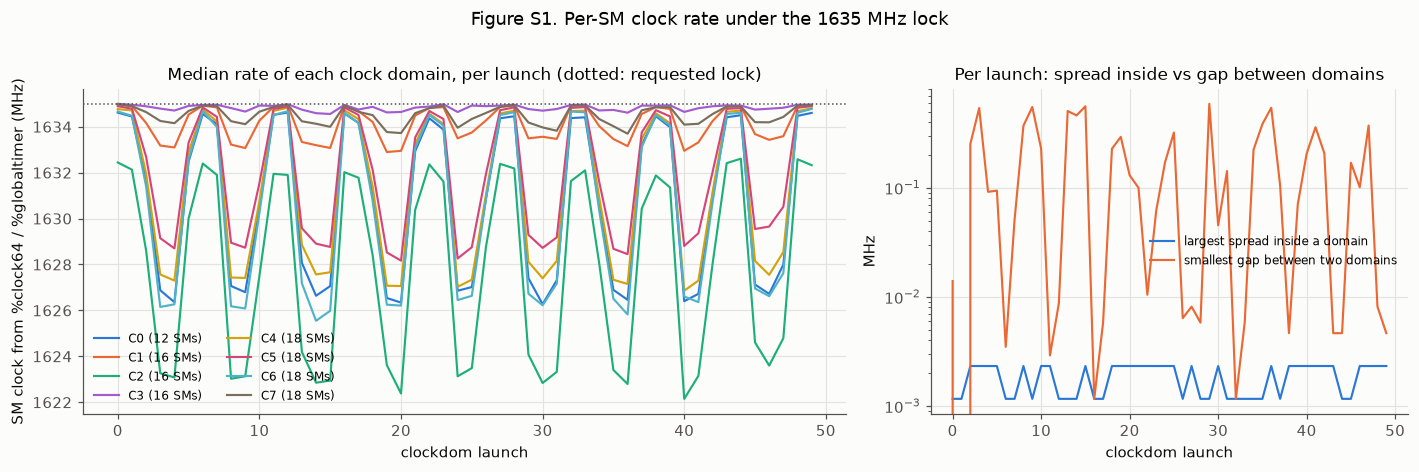

In [4]:
rate = clk.pivot(index="launch_idx", columns="smid", values="sm_mhz").reindex(columns=range(N))
d = np.abs(rate.values[:, :, None] - rate.values[:, None, :]).max(0)   # max over launches of |rate_i - rate_j|
TOL = 0.02
cparent = list(range(N))
def cfind(x):
    while cparent[x] != x: x = cparent[x]
    return x
for i in range(N):
    for j in range(i + 1, N):
        if d[i, j] < TOL:
            a, b = cfind(i), cfind(j)
            if a != b: cparent[max(a, b)] = min(a, b)
cdom = pd.Series(pd.factorize(pd.Series([cfind(i) for i in range(N)]), sort=True)[0], index=range(N), name="clock domain")
ids = sorted(cdom.unique())
within = pd.Series({k: d[np.ix_(cdom == k, cdom == k)].max() for k in ids})
between = np.array([[d[np.ix_(cdom == a, cdom == b)].max() if a != b else np.nan for b in ids] for a in ids])
dom_rate = pd.DataFrame({k: rate.loc[:, cdom == k].median(axis=1) for k in ids})
ct = pd.DataFrame({
    "SMs": cdom.value_counts().sort_index(),
    "median rate over launches (MHz)": dom_rate.median(),
    "range over launches (MHz)": dom_rate.max() - dom_rate.min(),
    "max spread inside the domain, any launch (MHz)": within,
    "closest other domain: max |Δ| over launches (MHz)": np.nanmin(between, axis=1),
}).rename_axis("clock domain")
ct.index = [f"C{k}" for k in ct.index]
display(ct)
span = clk.span_ns
print(f"window per SM: {span.min()}–{span.max()} ns, {clk.span_cycles.min()}–{clk.span_cycles.max()} cycles; "
      f"rates {clk.sm_mhz.min():.3f}–{clk.sm_mhz.max():.3f} MHz over {len(rate)} launches")
dd = dom_rate.max(axis=1) - dom_rate.min(axis=1)
print(f"difference between the fastest and the slowest clock domain within one launch: median {dd.median():.2f} MHz, "
      f"max {dd.max():.2f} MHz ({100 * dd.max() / 1635:.2f} % of the lock)")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
for k in ids:
    ax[0].plot(dom_rate.index, dom_rate[k], lw=1.4, color=PAL[k % 8], label=f"C{k} ({(cdom == k).sum()} SMs)")
ax[0].axhline(1635, ls=":", color=INK2, lw=1)
ax[0].set_xlabel("clockdom launch"); ax[0].set_ylabel("SM clock from %clock64 / %globaltimer (MHz)")
ax[0].set_title("Median rate of each clock domain, per launch (dotted: requested lock)")
ax[0].legend(fontsize=8, ncol=2, frameon=False)
spread = pd.DataFrame({k: rate.loc[:, cdom == k].max(axis=1) - rate.loc[:, cdom == k].min(axis=1) for k in ids})
gap = []
for li in rate.index:
    v = dom_rate.loc[li].sort_values().values
    gap.append(np.diff(v).min())
ax[1].semilogy(spread.index, spread.max(axis=1), color=PAL[0], lw=1.4, label="largest spread inside a domain")
ax[1].semilogy(rate.index, gap, color=PAL[1], lw=1.4, label="smallest gap between two domains")
ax[1].set_xlabel("clockdom launch"); ax[1].set_ylabel("MHz")
ax[1].set_title("Per launch: spread inside vs gap between domains"); ax[1].legend(fontsize=8, frameon=False)
fig.suptitle("Figure S1. Per-SM clock rate under the 1635 MHz lock", y=1.01)
plt.tight_layout(); plt.show()

### 3. Combining the two: GPCs

The cross-tabulation places each co-scheduling domain into the clock domain of its SMs.
- Every domain that hosts clusters of 3 or more lies entirely in one clock domain, and every clock domain contains exactly one such domain. The clock groups therefore reproduce the GPC structure seen by the cluster scheduler on all 124 SMs that it places in larger clusters.
- The four 2-SM domains fall into clock domains C0 (two of them), C4 and C5. Each GPC is the union of the co-scheduling domains in one clock domain.
- GPC labels G0–G7 are ordered by their smallest `%smid`.

In [5]:
xt = pd.crosstab(dom.map(lambda k: f"D{k}"), cdom.map(lambda k: f"C{k}"), rownames=["co-scheduling domain"], colnames=["clock domain"])
display(xt)
big = {k for k in dom.unique() if max_cs[dom == k].max() >= 4}
gpc_nb = pd.Series(pd.factorize(cdom, sort=True)[0], index=range(N))
same = (gpc_nb.values == mp.gpc.values).all()
print(f"co-scheduling domains able to host clusters >= 4: {len(big)}; each lies in one clock domain: "
      f"{all(cdom[dom == k].nunique() == 1 for k in big)}; clock domains containing exactly one of them: "
      f"{sum(len({k for k in dom[cdom == c].unique() if k in big}) == 1 for c in cdom.unique())} of {cdom.nunique()}")
print(f"GPC labels recomputed here agree with results/{EXP}__map.csv: {same}")
gpc = mp.gpc
G = sorted(gpc.unique())
orphan = mp.max_cs_observed <= 2

clock domain,C0,C1,C2,C3,C4,C5,C6,C7
co-scheduling domain,,,,,,,,
D0,8,0,0,0,0,0,0,0
D1,0,16,0,0,0,0,0,0
D10,0,0,0,0,0,2,0,0
D11,2,0,0,0,0,0,0,0
D2,0,0,16,0,0,0,0,0
D3,0,0,0,16,0,0,0,0
D4,0,0,0,0,16,0,0,0
D5,0,0,0,0,0,16,0,0
D6,0,0,0,0,0,0,18,0


co-scheduling domains able to host clusters >= 4: 8; each lies in one clock domain: True; clock domains containing exactly one of them: 8 of 8
GPC labels recomputed here agree with results/03__sm_gpc_topology__map.csv: True


### Figure 1 — the map

Panel (a) lays the 132 logical ids out in order, 12 per row, coloured by GPC. Panel (b) lists the SMs of each GPC. Hatched tiles are the 8 SMs (4 TPCs) that never shared a cluster with any SM outside their own TPC.

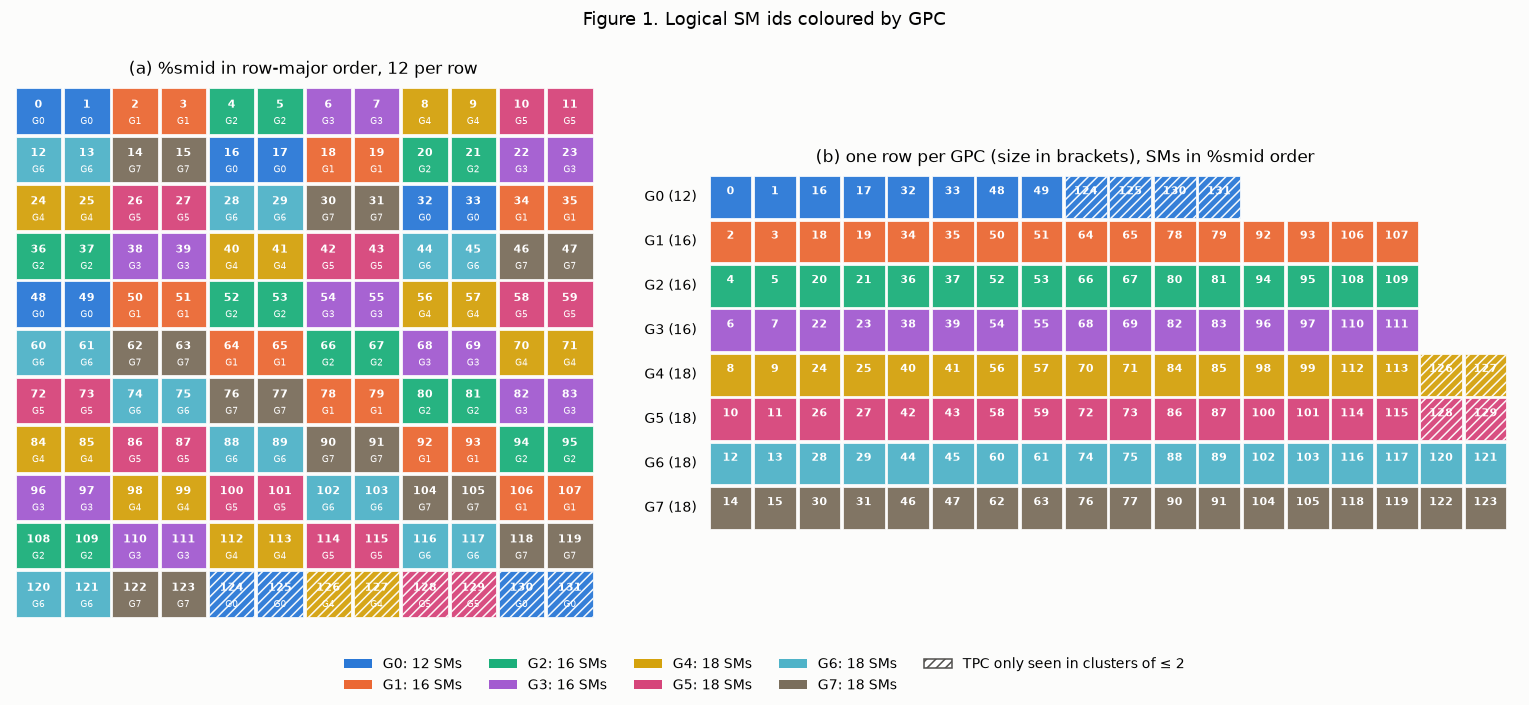

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(14, 6.4), gridspec_kw={"width_ratios": [12, 18.6]})
def tile(ax, x, y, s, label=True):
    c = PAL[gpc[s] % 8]
    ax.add_patch(Rectangle((x, y), 0.94, 0.94, facecolor=c, edgecolor="white", lw=0.5, hatch="////" if orphan[s] else None, alpha=0.95))
    ax.text(x + 0.47, y + 0.6, str(s), ha="center", va="center", fontsize=7.5, color="white", fontweight="bold")
    if label: ax.text(x + 0.47, y + 0.25, f"G{gpc[s]}", ha="center", va="center", fontsize=6, color="white")
ax = axs[0]
for s in range(N):
    tile(ax, s % 12, -(s // 12), s)
ax.set_xlim(-0.1, 12); ax.set_ylim(-10.1, 1.05); ax.set_aspect("equal"); ax.axis("off")
ax.set_title("(a) %smid in row-major order, 12 per row")
ax = axs[1]
for gi, g in enumerate(G):
    sms = sorted(gpc[gpc == g].index)
    for k, s in enumerate(sms):
        tile(ax, k, -gi, s, label=False)
    ax.text(-0.3, -gi + 0.47, f"G{g} ({len(sms)})", ha="right", va="center", fontsize=9)
ax.set_xlim(-2.2, 18.2); ax.set_ylim(-len(G) + 0.9, 1.05); ax.set_aspect("equal"); ax.axis("off")
ax.set_title("(b) one row per GPC (size in brackets), SMs in %smid order")
handles = [Patch(facecolor=PAL[g % 8], label=f"G{g}: {int((gpc == g).sum())} SMs") for g in G]
handles.append(Patch(facecolor="white", edgecolor=INK2, hatch="////", label="TPC only seen in clusters of ≤ 2"))
fig.legend(handles=handles, loc="lower center", ncol=5, frameon=False, fontsize=9)
fig.suptitle("Figure 1. Logical SM ids coloured by GPC", y=0.98)
plt.tight_layout(rect=(0, 0.07, 1, 0.97)); plt.show()

### Figure 2 — co-membership

Each cell counts the clusters (all sizes, all launches) that contained both SMs.
- In `%smid` order (a), the GPCs appear as diagonals 16 ids apart (14 ids apart above id 64).
- Grouped by GPC (b), the matrix is block-diagonal: no cluster ever spanned two GPCs.
- The small 2 × 2 blocks at the lower right of G0 (two of them), G4 and G5 are the restricted TPCs. They are drawn in the GPC their clock assigns them to, yet they never shared a cluster with any other SM of it.

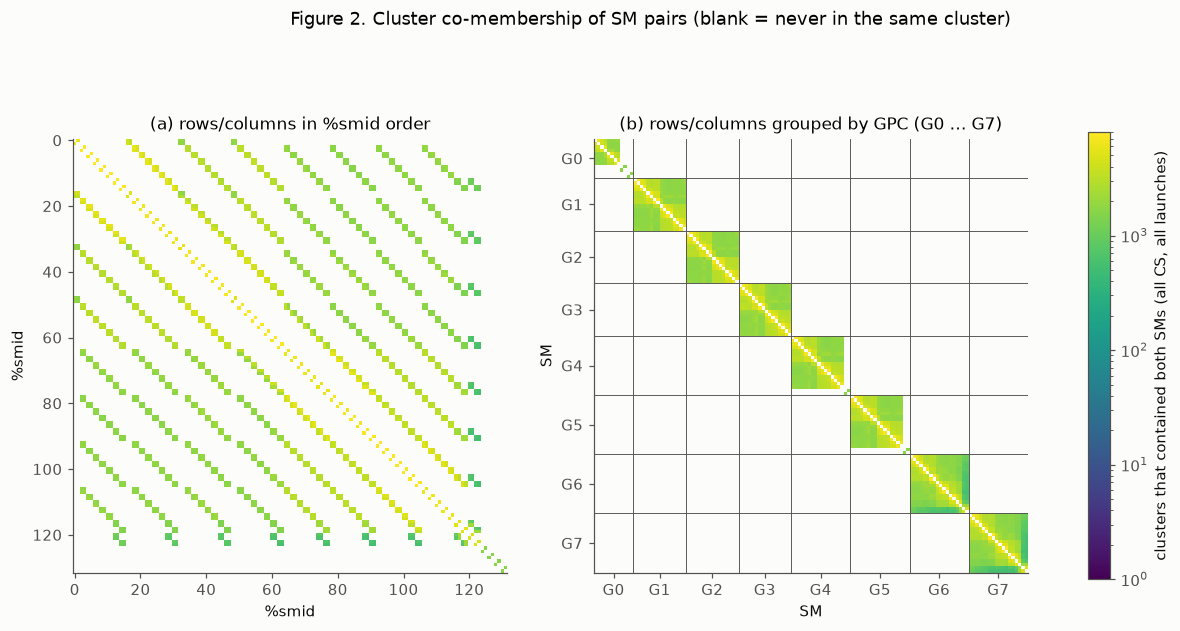

pairs counted: 2602800; inside one GPC: 2602800; across GPCs: 0
partners of the SMs only seen in clusters of <= 2: 124: [125]; 125: [124]; 126: [127]; 127: [126]; 128: [129]; 129: [128]; 130: [131]; 131: [130]


In [7]:
order = [s for g in G for s in sorted(gpc[gpc == g].index)]
fig, axs = plt.subplots(1, 2, figsize=(14, 6.6))
norm = LogNorm(vmin=1, vmax=adj.max())
cmap = plt.get_cmap("viridis").copy(); cmap.set_bad(SURF)
for ax, idx, title in [(axs[0], list(range(N)), "(a) rows/columns in %smid order"),
                       (axs[1], order, "(b) rows/columns grouped by GPC (G0 … G7)")]:
    m = adj[np.ix_(idx, idx)].astype(float); m[m == 0] = np.nan
    im = ax.imshow(m, cmap=cmap, norm=norm, interpolation="nearest")
    ax.set_title(title); ax.grid(False)
    ax.set_xlabel("SM" if idx is order else "%smid"); ax.set_ylabel("SM" if idx is order else "%smid")
    if idx is order:
        b = np.cumsum([0] + [int((gpc == g).sum()) for g in G])
        for x in b[1:-1]:
            ax.axhline(x - 0.5, color=INK2, lw=0.6); ax.axvline(x - 0.5, color=INK2, lw=0.6)
        ax.set_xticks((b[:-1] + b[1:]) / 2 - 0.5); ax.set_xticklabels([f"G{g}" for g in G])
        ax.set_yticks((b[:-1] + b[1:]) / 2 - 0.5); ax.set_yticklabels([f"G{g}" for g in G])
fig.colorbar(im, ax=axs, shrink=0.8, label="clusters that contained both SMs (all CS, all launches)")
fig.suptitle("Figure 2. Cluster co-membership of SM pairs (blank = never in the same cluster)", y=0.97)
plt.show()
inside = sum(adj[np.ix_(gpc == g, gpc == g)].sum() for g in G) // 2
print(f"pairs counted: {adj.sum() // 2}; inside one GPC: {inside}; across GPCs: {adj.sum() // 2 - inside}")
od = [(s, sorted(np.nonzero(adj[s])[0].tolist())) for s in mp.index[orphan]]
print("partners of the SMs only seen in clusters of <= 2:", "; ".join(f"{s}: {p}" for s, p in od))

### Figure 3 — GPC sizes

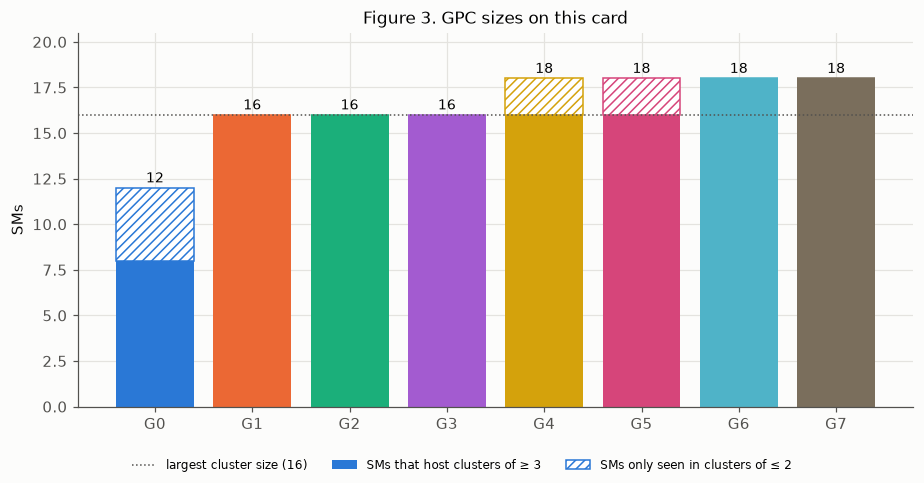

GPC sizes [18, 18, 18, 18, 16, 16, 16, 12] (sum 132); cluster-capable sizes [18, 18, 16, 16, 16, 16, 16, 8] (sum 124); GPCs that hosted a cluster of 16: 7


In [8]:
cap = pd.Series({g: int(((gpc == g) & ~orphan).sum()) for g in G})
orp = pd.Series({g: int(((gpc == g) & orphan).sum()) for g in G})
fig, ax = plt.subplots(figsize=(8.5, 4.4))
ax.set_axisbelow(True)
x = np.arange(len(G))
ax.bar(x, cap, color=[PAL[g % 8] for g in G], label="SMs that host clusters of ≥ 3")
ax.bar(x, orp, bottom=cap, color="white", edgecolor=[PAL[g % 8] for g in G], hatch="////", label="SMs only seen in clusters of ≤ 2")
for xi, g in zip(x, G):
    ax.text(xi, cap[g] + orp[g] + 0.3, f"{cap[g] + orp[g]}", ha="center", fontsize=9)
ax.axhline(16, ls=":", color=INK2, lw=1, label="largest cluster size (16)")
ax.set_xticks(x); ax.set_xticklabels([f"G{g}" for g in G]); ax.set_ylabel("SMs"); ax.set_ylim(0, 20.5)
ax.set_title("Figure 3. GPC sizes on this card")
fig.legend(frameon=False, fontsize=8, loc="lower center", ncol=3)
plt.tight_layout(rect=(0, 0.06, 1, 1)); plt.show()
print(f"GPC sizes {sorted((cap + orp).tolist(), reverse=True)} (sum {int((cap + orp).sum())}); "
      f"cluster-capable sizes {sorted(cap.tolist(), reverse=True)} (sum {int(cap.sum())}); "
      f"GPCs that hosted a cluster of 16: {int(mp.groupby('gpc').hosts_cs16.first().sum())}")

### 4. Cross-check with the hardware's per-GPC cluster counters

For each profiled launch, the map predicts the number of clusters per GPC:
- In a GPC with `c` cluster-capable SMs and `k` CTAs per SM, the Default policy never puts two CTAs of a cluster on one SM. It therefore fits ⌊k·c / CS⌋ clusters (0 if CS > c).
- Each restricted TPC adds `k` clusters of 2.

The table compares the predicted sum, minimum, maximum and average over the eight GPCs with Nsight Compute's counters.

These short kernels (≈ 65 µs) make `sm__cycles_elapsed.avg.per_second` read below the lock, because the kernel duration includes about 1–2 µs in which SM cycles are not counted. NVML reported 1635 MHz and no throttle reason after every profiled launch, and the cluster counts do not depend on the clock.

The driver's MIG profile table is shown below the comparison. It is queried without enabling MIG.

In [9]:
k_per_sm = lambda smem: 1 if smem >= 120 * 1024 else 2
pred = []
for _, n in ncu.iterrows():
    k, cs = k_per_sm(n.smem_bytes), int(n.cs)
    per = [(k * cap[g] // cs if cs <= cap[g] else 0) + (k * orp[g] // 2 if cs == 2 else 0) for g in G]
    pred.append(per)
tab = pd.DataFrame({
    "CS": ncu.cs.values, "CTAs/SM": [k_per_sm(s) for s in ncu.smem_bytes], "grid": ncu.grid_blocks.values,
    "API max active clusters": ncu.api_max_active_clusters.values,
    "ncu sum": ncu["gpc__cgas_launched.sum"].values, "map sum": [sum(p) for p in pred],
    "ncu min / max": [f"{a:.0f} / {b:.0f}" for a, b in zip(ncu["gpc__cgas_launched.min"], ncu["gpc__cgas_launched.max"])],
    "map min / max": [f"{min(p)} / {max(p)}" for p in pred],
    "ncu avg": ncu["gpc__cgas_launched.avg"].values, "map avg": [sum(p) / len(G) for p in pred],
    "map per GPC (G0 … G7)": [" ".join(map(str, p)) for p in pred],
})
display(tab)
print(f"GPC instances counted by ncu (sum / avg): {sorted(set((ncu['gpc__cgas_launched.sum'] / ncu['gpc__cgas_launched.avg']).round(1)))}; "
      f"SM clock during profiling {ncu['sm__cycles_elapsed.avg.per_second'].min() / 1e6:.1f}–{ncu['sm__cycles_elapsed.avg.per_second'].max() / 1e6:.1f} MHz")

mig = open(F + "mig.txt").read().split("=== ")[-1]
prof = re.findall(r"MIG (\S+)\s+(\d+)\s+(\d+)/(\d+)\s+([\d.]+)\s+\w+\s+(\d+)", mig)
mt = pd.DataFrame(prof, columns=["profile", "id", "free", "max instances", "memory GiB", "SMs"]).drop(columns="free")
mt["SMs × max instances"] = mt.SMs.astype(int) * mt["max instances"].astype(int)
display(mt.set_index("profile").style.set_caption("MIG GPU-instance profiles reported by the driver (queried with MIG disabled)"))

,CS,CTAs/SM,grid,API max active clusters,ncu sum,map sum,ncu min / max,map min / max,ncu avg,map avg,map per GPC (G0 … G7)
0,2,1,132,66,66,66,6 / 9,6 / 9,8.25,8.250,6 8 8 8 9 9 9 9
1,3,1,117,39,39,39,2 / 6,2 / 6,4.88,4.875,2 5 5 5 5 5 6 6
2,4,1,120,30,30,30,2 / 4,2 / 4,3.75,3.750,2 4 4 4 4 4 4 4
3,8,1,120,15,15,15,1 / 2,1 / 2,1.88,1.875,1 2 2 2 2 2 2 2
4,16,1,112,7,7,7,0 / 1,0 / 1,0.88,0.875,0 1 1 1 1 1 1 1
5,2,2,264,132,132,132,12 / 18,12 / 18,16.50,16.500,12 16 16 16 18 18 18 18
6,3,2,237,79,79,79,5 / 12,5 / 12,9.88,9.875,5 10 10 10 10 10 12 12
7,4,2,248,62,62,62,4 / 9,4 / 9,7.75,7.750,4 8 8 8 8 8 9 9
8,8,2,240,30,30,30,2 / 4,2 / 4,3.75,3.750,2 4 4 4 4 4 4 4
9,16,2,224,14,14,14,0 / 2,0 / 2,1.75,1.750,0 2 2 2 2 2 2 2


GPC instances counted by ncu (sum / avg): [8.0]; SM clock during profiling 1590.0–1610.5 MHz


,id,max instances,memory GiB,SMs,SMs × max instances
profile,,,,,
1g.12gb,19,7,10.75,16,112
1g.12gb+me,20,1,10.75,16,16
1g.24gb,15,4,21.62,26,104
2g.24gb,14,3,21.62,32,96
3g.47gb,9,2,46.38,60,120
4g.47gb,5,1,46.38,64,64
7g.94gb,0,1,93.12,132,132


### 5. TPC mates

Under the hypothesis that `%smid` 2t and 2t+1 are one TPC, the tables count how often the hardware puts the two CTAs of a cluster of 2 (or ranks 2r and 2r+1 of a larger cluster) on such a pair.
- In a one-wave launch every cluster starts on an idle GPU.
- In three-wave launches, later clusters take whichever SMs have just been freed.

In [10]:
c2 = clusters[clusters.cs == 2]
e2 = edges[edges.cs == 2].copy()
rows = []
for (w, sm, th), g in c2.groupby(["waves", "smem_bytes", "block_threads"]):
    rows.append({"waves": w, "smem": f"{sm // 1024} KB", "threads": th, "clusters": len(g),
                 "both SMs in one TPC (2k, 2k+1)": f"{100 * g.tpc_pairs.mean():.1f} %"})
display(pd.DataFrame(rows).set_index(["waves", "smem", "threads"]).style.set_caption("clusters of 2"))
rows = []
for cs in [4, 8, 16]:
    for w in [1, 3]:
        g = clusters[(clusters.cs == cs) & (clusters.waves == w)]
        rows.append({"CS": cs, "waves": w, "rank pairs (2r, 2r+1)": len(g) * cs // 2,
                     "in one TPC": f"{100 * g.tpc_pairs.sum() / (len(g) * cs // 2):.1f} %"})
display(pd.DataFrame(rows).set_index(["CS", "waves"]).style.set_caption("larger clusters: ranks 2r and 2r+1"))
partners = {s: set(np.nonzero(adj[s])[0]) for s in range(N)}
print("SMs whose only cluster partner is smid ^ 1:", [s for s in range(N) if partners[s] == {s ^ 1}])

SMs whose only cluster partner is smid ^ 1: [124, 125, 126, 127, 128, 129, 130, 131]


### 6. The map

The first table gives the composition per GPC in TPCs (TPC t = SMs 2t, 2t+1). Below it is the GPC of every TPC in id order, which shows how the logical ids are assigned. The last table is the content of `results/03__sm_gpc_topology__map.csv` for this card.
- `gpc`: the physical GPC.
- `cosched_domain` / `max_cs_observed`: what the cluster scheduler does with each SM.
- `clock_domain`: the clock group.
- `partition` / `subnode`: L2 affinity, not measured here.

In [11]:
tpc = pd.Series(np.arange(N) // 2, index=range(N))
rows = []
for g in G:
    sms = sorted(gpc[gpc == g].index)
    t = sorted(set(tpc[sms]))
    rows.append({"GPC": f"G{g}", "SMs": len(sms), "TPCs": len(t), "cluster-capable SMs": int(cap[g]),
                 "hosts CS 16": int(mp.hosts_cs16[sms[0]]), "TPC ids (%smid // 2)": " ".join(map(str, t)),
                 "TPCs only in clusters ≤ 2": " ".join(str(x) for x in t if orphan[2 * x]) or "—"})
display(pd.DataFrame(rows).set_index("GPC"))
seq = "".join(f"{gpc[2 * t]}" for t in range(N // 2))
print("GPC of TPC 0, 1, 2, … (TPC t = SMs 2t, 2t+1):")
for i in range(0, len(seq), 16):
    print(f"  TPC {i:2d}–{min(i + 15, len(seq) - 1):2d}: " + " ".join(seq[i:i + 16]))
cols = ["gpc", "gpc_size", "hosts_cs16", "tpc_mate_hyp", "cosched_domain", "cosched_domain_size", "max_cs_observed", "clock_domain", "notes"]
display(mp[cols].T.style.set_caption(f"results/{EXP}__map.csv (one column per %smid; partition/subnode not filled here)"))

,SMs,TPCs,cluster-capable SMs,hosts CS 16,TPC ids (%smid // 2),TPCs only in clusters ≤ 2
GPC,,,,,,
G0,12,6,8,0,0 8 16 24 62 65,62 65
G1,16,8,16,1,1 9 17 25 32 39 46 53,—
G2,16,8,16,1,2 10 18 26 33 40 47 54,—
G3,16,8,16,1,3 11 19 27 34 41 48 55,—
G4,18,9,16,1,4 12 20 28 35 42 49 56 63,63
G5,18,9,16,1,5 13 21 29 36 43 50 57 64,64
G6,18,9,18,1,6 14 22 30 37 44 51 58 60,—
G7,18,9,18,1,7 15 23 31 38 45 52 59 61,—


GPC of TPC 0, 1, 2, … (TPC t = SMs 2t, 2t+1):
  TPC  0–15: 0 1 2 3 4 5 6 7 0 1 2 3 4 5 6 7
  TPC 16–31: 0 1 2 3 4 5 6 7 0 1 2 3 4 5 6 7
  TPC 32–47: 1 2 3 4 5 6 7 1 2 3 4 5 6 7 1 2
  TPC 48–63: 3 4 5 6 7 1 2 3 4 5 6 7 6 7 0 4
  TPC 64–65: 5 0


smid,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89,90,91,92,93,94,95,96,97,98,99,100,101,102,103,104,105,106,107,108,109,110,111,112,113,114,115,116,117,118,119,120,121,122,123,124,125,126,127,128,129,130,131
gpc,0,0,1,1,2,2,3,3,4,4,5,5,6,6,7,7,0,0,1,1,2,2,3,3,4,4,5,5,6,6,7,7,0,0,1,1,2,2,3,3,4,4,5,5,6,6,7,7,0,0,1,1,2,2,3,3,4,4,5,5,6,6,7,7,1,1,2,2,3,3,4,4,5,5,6,6,7,7,1,1,2,2,3,3,4,4,5,5,6,6,7,7,1,1,2,2,3,3,4,4,5,5,6,6,7,7,1,1,2,2,3,3,4,4,5,5,6,6,7,7,6,6,7,7,0,0,4,4,5,5,0,0
gpc_size,12,12,16,16,16,16,16,16,18,18,18,18,18,18,18,18,12,12,16,16,16,16,16,16,18,18,18,18,18,18,18,18,12,12,16,16,16,16,16,16,18,18,18,18,18,18,18,18,12,12,16,16,16,16,16,16,18,18,18,18,18,18,18,18,16,16,16,16,16,16,18,18,18,18,18,18,18,18,16,16,16,16,16,16,18,18,18,18,18,18,18,18,16,16,16,16,16,16,18,18,18,18,18,18,18,18,16,16,16,16,16,16,18,18,18,18,18,18,18,18,18,18,18,18,12,12,18,18,18,18,12,12
hosts_cs16,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,1,1,0,0
tpc_mate_hyp,1,0,3,2,5,4,7,6,9,8,11,10,13,12,15,14,17,16,19,18,21,20,23,22,25,24,27,26,29,28,31,30,33,32,35,34,37,36,39,38,41,40,43,42,45,44,47,46,49,48,51,50,53,52,55,54,57,56,59,58,61,60,63,62,65,64,67,66,69,68,71,70,73,72,75,74,77,76,79,78,81,80,83,82,85,84,87,86,89,88,91,90,93,92,95,94,97,96,99,98,101,100,103,102,105,104,107,106,109,108,111,110,113,112,115,114,117,116,119,118,121,120,123,122,125,124,127,126,129,128,131,130
cosched_domain,0,0,1,1,2,2,3,3,4,4,5,5,6,6,7,7,0,0,1,1,2,2,3,3,4,4,5,5,6,6,7,7,0,0,1,1,2,2,3,3,4,4,5,5,6,6,7,7,0,0,1,1,2,2,3,3,4,4,5,5,6,6,7,7,1,1,2,2,3,3,4,4,5,5,6,6,7,7,1,1,2,2,3,3,4,4,5,5,6,6,7,7,1,1,2,2,3,3,4,4,5,5,6,6,7,7,1,1,2,2,3,3,4,4,5,5,6,6,7,7,6,6,7,7,8,8,9,9,10,10,11,11
cosched_domain_size,8,8,16,16,16,16,16,16,16,16,16,16,18,18,18,18,8,8,16,16,16,16,16,16,16,16,16,16,18,18,18,18,8,8,16,16,16,16,16,16,16,16,16,16,18,18,18,18,8,8,16,16,16,16,16,16,16,16,16,16,18,18,18,18,16,16,16,16,16,16,16,16,16,16,18,18,18,18,16,16,16,16,16,16,16,16,16,16,18,18,18,18,16,16,16,16,16,16,16,16,16,16,18,18,18,18,16,16,16,16,16,16,16,16,16,16,18,18,18,18,18,18,18,18,2,2,2,2,2,2,2,2
max_cs_observed,8,8,16,16,16,16,16,16,16,16,16,16,16,16,16,16,8,8,16,16,16,16,16,16,16,16,16,16,16,16,16,16,8,8,16,16,16,16,16,16,16,16,16,16,16,16,16,16,8,8,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,2,2,2,2,2,2,2,2
clock_domain,0,0,1,1,2,2,3,3,4,4,5,5,6,6,7,7,0,0,1,1,2,2,3,3,4,4,5,5,6,6,7,7,0,0,1,1,2,2,3,3,4,4,5,5,6,6,7,7,0,0,1,1,2,2,3,3,4,4,5,5,6,6,7,7,1,1,2,2,3,3,4,4,5,5,6,6,7,7,1,1,2,2,3,3,4,4,5,5,6,6,7,7,1,1,2,2,3,3,4,4,5,5,6,6,7,7,1,1,2,2,3,3,4,4,5,5,6,6,7,7,6,6,7,7,0,0,4,4,5,5,0,0
notes,card serial N/A; only in clusters of <= 8; GPC from clock domain,card serial N/A; only in clusters of <= 8; GPC from clock domain,card serial N/A,card serial N/A,card serial N/A,card serial N/A,card serial N/A,card serial N/A,card serial N/A; only in clusters of <= 16; GPC from clock domain,card serial N/A; only in clusters of <= 16; GPC from clock domain,card serial N/A; only in clusters of <= 16; GPC from clock domain,card serial N/A; only in clusters of <= 16; GPC from clock domain,card serial N/A,card serial N/A,card serial N/A,card serial N/A,card serial N/A; only in clusters of <= 8; GPC from clock domain,card serial N/A; only in clusters of <= 8; GPC from clock domain,card serial N/A,card serial N/A,card serial N/A,card serial N/A,card serial N/A,card serial N/A,card serial N/A; only in clusters of <= 16; GPC from clo

## Insights

- **This card has 8 GPCs of 18, 18, 18, 18, 16, 16, 16 and 12 SMs** (66 TPCs: 9, 9, 9, 9, 8, 8, 8, 6). Three independent observations agree on this:
  - Cluster co-membership places 124 SMs into eight groups. Of 2.6 million cases of two SMs sharing a cluster, none crossed a group.
  - Exactly eight clock domains cover all 132 SMs, and each contains exactly one of those groups.
  - The hardware's per-GPC cluster counters count eight GPC units and match the map's predicted sum, minimum, maximum and average in all ten profiled configurations.

  The driver's MIG profile table is consistent with it: the smallest GPU instance has 16 SMs and at most 7 of them exist (112 SMs). That matches the 7 GPCs with ≥ 16 cluster-capable SMs.
- **What clusters can use is smaller than the GPCs: 18, 18, 16, 16, 16, 16, 16 and 8 SMs (124 SMs).**
  - Four TPCs (SMs 124–131, TPCs 62–65) never shared a cluster with any SM outside their own TPC in 3000 launches. That includes clusters of 3 and launches that allow 2 CTAs per SM. Their only partner was always `smid ^ 1`, so cluster placement alone sees them as four separate 2-SM domains.
  - Their clock and the per-GPC counters put two of them in the 12-SM GPC G0 and one each in the 18-SM GPCs G4 and G5. The counters require exactly two in the smallest GPC: its count of clusters of 2 at 2 CTAs/SM is 12, which is 8 cluster-capable SMs plus 2 restricted TPCs. The clock assigns the other two.
  - So these TPCs are part of their GPC physically but are treated as separate units by the cluster scheduler; why is not visible from these measurements.
  - Consequences for cluster-based measurements: clusters of ≥ 3 never include SMs 124–131, SM-pair data for them exists only within their own TPC, 7 GPCs (112 SMs) can host a cluster of 16, and G0 hosts at most one cluster of 8 (or two of 4) at 1 CTA/SM.
- **Logical ids follow a round-robin over GPCs, with the restricted TPCs numbered last.**
  - TPCs 0–31 cycle through G0…G7.
  - G0 runs out of cluster-capable TPCs after four, so TPCs 32–59 cycle through G1…G7.
  - TPCs 60–61 are the ninth TPCs of G6 and G7, and TPCs 62–65 are the restricted ones (G0, G4, G5, G0).

  `%smid // 2 mod 8` therefore gives the GPC only below id 64. Code that needs the GPC must use the map, not a formula.
- **The ids 2t and 2t+1 behave as TPC mates.**
  - Every cluster of 2 placed on an idle GPU, and every rank pair (2r, 2r+1) of one-wave clusters of 4, 8 and 16, landed on such a pair (100 %, 26 400 clusters and 70 800 rank pairs).
  - The restricted TPCs pair only with `smid ^ 1`.
  - Placement can be explained by the scheduler filling TPCs, so the pairing is consistent with, but does not prove, a shared TPC. A latency signature between the two SMs would be direct evidence.
- **GPCs run at measurably different clocks under the same lock.**
  - Within one GPC the effective SM clock is identical to 0.002 MHz in every launch.
  - Between GPCs it differs by a median of 6.4 MHz and up to 12.5 MHz (0.76 %) in one launch (1622–1635 MHz overall), and it varies from launch to launch in a recurring pattern.
  - A cycle count converts to nanoseconds with a GPC-dependent factor. Cross-SM comparisons in cycles at the sub-percent level should use the clock of the GPC that produced them.
- **Limitations.**
  - No privileged ground truth was available: the floor-sweeping masks were not read, and MIG was not enabled.
  - "One clock domain = one GPC" is an inference. It holds for all 124 SMs whose GPC the cluster scheduler reveals, and the counters confirm the GPC sizes. The GPC of the 8 restricted SMs rests on it and on the counter constraint above.
  - The per-GPC counters are available only as roll-ups, so they confirm the set of GPC sizes, not which logical ids sit in which unit.
  - L2 partition affinity (`partition`, `subnode`) is not part of this measurement and is left empty in the map.